# Data Analysis: Help the Doctor (Group 51)

Material for **Data → Data Analysis** in `paper/51.tex`: describe the dataset (class distribution, relevant statistics) and give **at least 2 concrete observations**.

| § | Question |
|---|---|
| 1 | Can `train.csv` be read as it is? |
| 2 | How do we repair it? |
| 3 | How big is the data, and what is missing? |
| 4 | How are classes and text lengths distributed? |
| 5 | What does a label actually describe? |
| 6 | How do records, fields and train/test relate? |
| 7 | Which words characterise each class? What needs cleaning? |
| 8 | Summary for the paper |

In [2]:
import csv
import re
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DATA = Path("../../data")                        # original_train.csv (= train.csv) and original_test.csv (= test_no_labels.csv)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)  # figures for the paper (PDF)
TARGET = "medical_specialty"
TEXT_COLS = ["description", "sample_name", "transcription", "keywords"]

pd.set_option("display.max_colwidth", 80)

In [3]:
# Plotting helpers: every figure has the same look and fits one column of the paper
COLOR, INK = "#2a78d6", "#52514e"
SHORT = {"Cardiovascular-Pulmonary": "Cardio-Pulm", "General Medicine": "Gen. Medicine",
         "Gastroenterology": "Gastro", "Obstetrics-Gynecology": "Obs-Gyn",
         "Psychiatry-Psychology": "Psych"}
plt.rcParams.update({"figure.dpi": 130, "savefig.bbox": "tight", "font.size": 7,
                     "axes.titlesize": 8, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})

def short(labels):
    return [SHORT.get(label, label) for label in labels]

def barh(ax, labels, values, fmt="{:,.0f}", title="", xlabel=""):
    """Horizontal bars, first label on top, value written after each bar."""
    y = np.arange(len(values))
    ax.barh(y, values, color=COLOR, height=0.7)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, values):
        ax.text(v, yi, " " + fmt.format(v), va="center", fontsize=6, color=INK)
    ax.set_xlim(0, max(values) * 1.18)
    ax.set(title=title, xlabel=xlabel)

def heatmap(ax, table, title="", vmax=None, hide=None):
    """Annotated heatmap. NaN cells stay blank; cells equal to `hide` are not annotated."""
    values = table.to_numpy(dtype=float)
    vmax = vmax or np.nanmax(values)
    ax.imshow(np.ma.masked_invalid(values), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=45, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for (r, c), v in np.ndenumerate(values):
        if not np.isnan(v) and v != hide:
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.6 * vmax else "#0b0b0b")
    ax.set_title(title)

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf")
    plt.show()

## 1. Reading `train.csv` the naive way

First attempt: `pd.read_csv`. As in Lab 2 ("was this enough to get the **exact** number of characters?"), we start by counting the labels.

In [4]:
naive = pd.read_csv(DATA / "original_train.csv", sep=";")
print(f"rows: {len(naive):,} | distinct labels: {naive[TARGET].nunique()} (expected 12)")

bogus = naive[TARGET].str.len() > 30
desc_len = naive["description"].str.len()
print("rows whose 'label' is text:", naive.index[bogus].tolist(),
      [label[:25] + "..." for label in naive.loc[bogus, TARGET]])
print("rows whose description has > 5,000 chars:", desc_len[desc_len > 5000].astype(int).to_dict())

rows: 2,616 | distinct labels: 15 (expected 12)
rows whose 'label' is text: [932, 2052, 2281] ['d is open about may be ro...', 'ypothyroidism secondary t...', 'ted and this was used to ...']
rows whose description has > 5,000 chars: {159: 9722, 710: 28647, 931: 32745, 1058: 28973, 2051: 32748, 2280: 32751}


**What we see.** 15 labels, 3 of them are pieces of clinical text, and 6 descriptions of 9.7k–32.8k characters. Each text "label" comes right after a description that stops at ~32,759 characters (931→932, 2051→2052, 2280→2281): one record's text continues on the next row. 32,759 is just under Excel's 32,767-character cell limit, so the file probably went through a spreadsheet. The parsed table hides the cause, so we go to the **raw lines**.

## 2. Repairing `train.csv` line by line

A healthy record is one physical line with exactly 4 `;` separators.

In [5]:
path = DATA / "original_train.csv"
text = path.read_text(encoding="utf-8")

lines = text.splitlines()

print(f"Number of lines: {len(lines)}")
print(f"First line: {lines[0]}")

Number of lines: 2673
First line: medical_specialty;description;sample_name;transcription;keywords


In [6]:
suspicious = []

for number, line in enumerate(lines[1:], start=2):
    if line.count(";") != 4:
        suspicious.append((number, line.count(";"), line[:10]))

print("Suspicious lines:", len(suspicious))
print(suspicious[:10])

Suspicious lines: 13
[(161, 1, 'Cardiovasc'), (163, 6, 'Psychiatry'), (714, 1, 'General Me'), (947, 1, 'Neurosurge'), (961, 6, 'General Me'), (1088, 1, 'Obstetrics'), (1096, 6, 'General Me'), (2089, 1, 'Surgery;"T'), (2100, 6, 'Neurology;'), (2329, 1, 'Surgery;"A')]


In [7]:
odd_quotes = []

for number, line in enumerate(lines[1:], start=2):
    if line.count('"') % 2 != 0:
        odd_quotes.append((number, line.count('"'), line[:10]))

print("Lines with an odd number of quotes:", len(odd_quotes))
print(odd_quotes)

Lines with an odd number of quotes: 14
[(161, 1, 'Cardiovasc'), (163, 7, 'Psychiatry'), (714, 1, 'General Me'), (726, 13, 'Obstetrics'), (947, 1, 'Neurosurge'), (961, 1, 'General Me'), (1088, 1, 'Obstetrics'), (1096, 7, 'General Me'), (2089, 1, 'Surgery;"T'), (2100, 1, 'Neurology;'), (2329, 1, 'Surgery;"A'), (2337, 1, 'Surgery; D'), (2394, 1, 'Surgery;"L'), (2395, 23, 'Radiology;')]


**What we see.** 13 lines do not have 4 `;`, and 14 have an odd number of `"`: a quote is opened on one line and closed on another. Looking at them, there are three patterns:

| pattern | lines | what pandas does |
|---|---|---|
| **fragment**: label + `"` + the first 120–230 characters of a description, nothing else | 161, 714, 947, 1088, 2089, 2329, 2394 | opens a quoted field... |
| **closing line**: a record holding the `"` that closes it (extra `;` at the end) | 163, 726, 961, 1096, 2100, 2337, 2395 | ...that only closes here, so every record in between becomes one giant `description` |
| **cut + continuation**: a transcription cut mid-word (`...The wou";;;` / `d is open about...;;;;`) | 961→962, 2100→2101, 2337→2338 | reads the second half as a new row whose "label" is text |

So the plan: find the real labels, then classify every line as a new record, a fragment or a continuation.

In [8]:
header, body = lines[0], lines[1:]
LABELS = []
for number, line in enumerate(body, start=2):
    first = line.split(";", 1)[0]
    if first not in LABELS and len(first) < 100:
        LABELS.append(first)
print(LABELS)

['Cardiovascular-Pulmonary', 'Gastroenterology', 'Psychiatry-Psychology', 'Dermatology', 'General Medicine', 'Ophthalmology', 'Neurosurgery', 'Orthopedic', 'Surgery', 'Radiology', 'Obstetrics-Gynecology', 'Neurology']


In [9]:
new_record_lines = []
continuation_lines = []

for line_number, line in enumerate(body, start=2):
    first = line.split(";", 1)[0].strip()

    if first in LABELS:
        new_record_lines.append((line_number, line))
    else:
        continuation_lines.append((line_number, line))

print(f"NEW: {len(new_record_lines)}")
print(f"CONTINUATION: {len(continuation_lines)}")

NEW: 2669
CONTINUATION: 3


In [10]:
print("Examples of lines that start a record:")
for line_number, line in new_record_lines[:3]:
    print(line_number, line[:120])

print("\nExamples of lines that do not start a record:")
for line_number, line in continuation_lines[:5]:
    print(line_number, line[:120])

Examples of lines that start a record:
2 Cardiovascular-Pulmonary; Chest pain, possible syncopal spells.  She has been having multiple cardiovascular complaints 
3 Cardiovascular-Pulmonary;The patient is 14 months old, comes in with a chief complaint of difficulty breathing.; Difficu
4 Cardiovascular-Pulmonary; Fiberoptic bronchoscopy, diagnostic.  Hemoptysis and history of lung cancer.  Tumor occluding 

Examples of lines that do not start a record:
962 d is open about may be roughly a centimeter in the inside of the flap.  He was seen by his medical primary care physicia
2101 "ypothyroidism secondary to hyperthyroidism and irradiation, possible lumbar stenosis.  He reports he experienced a sing
2338 ted and this was used to aspirate approximately 30 cc of serosanguineous fluid from the cystic structure.  Next, the nee


In [11]:
for line_number, line in continuation_lines[:20]:
    print(
        line_number,
        "separators =", line.count(";"),
        "quotes =", line.count('"'),
        repr(line[:40])
    )

962 separators = 4 quotes = 0 'd is open about may be roughly a centime'
2101 separators = 4 quotes = 16 '"ypothyroidism secondary to hyperthyroid'
2338 separators = 4 quotes = 0 'ted and this was used to aspirate approx'


**What we see.** Only 3 lines do not start with a label: the second halves of the cut transcriptions. They already have 4 `;` (they end in `;;;;`), which is why they look like records. The fragments do start with a label, so they need their own rule (1 `;` and an unclosed quote).

In [12]:
def classify_line(line):
    first_field = line.split(";", 1)[0].strip()

    if line.count(";") == 1 and line.count('"') % 2 == 1:
        return "fragment"

    if first_field in LABELS:
        return "new_record"

    if (first_field not in LABELS) and line.endswith(";;;;"):
        return "continuation"

    return "unknown"

In [13]:
line_types = Counter(classify_line(line) for line in body)
line_types

Counter({'new_record': 2662, 'fragment': 7, 'continuation': 3})

Every line falls in one of the three types (2,662 + 7 + 3 = 2,672, no "unknown"). Repair rules: **drop** fragments, **glue** each continuation to the previous record (removing the `"` and the extra `;` around the cut), and remove the extra `;` and closing `"` from the closing lines.

In [14]:
def parse_broken_lines(line, type="current"):
    # "prev": first half of a cut record -> remove its trailing ';' and the quote before them
    # "current": a closing line (or a glued record) -> remove the extra ';' and the closing quote
    if type == "prev":
        while line.endswith(";"):
            line = line[:-1]
        if line.endswith('"'):
            line = line[:-1]
    elif type == "current":
        while line.endswith(";") and line.count(";") > 4:
            line = line[:-1]
        if line.endswith('"'):
            line = line[:-1]
    return line

In [15]:
records = []

for line_number, line in enumerate(body, start=2):
    kind = classify_line(line)

    if kind == "fragment":
        continue                                         # drop

    elif (kind == "new_record") and (line.count(";") == 4):
        records.append(line)                             # healthy line

    elif kind == "continuation":                         # glue to the previous record
        line_before = records[-1]
        line_before = parse_broken_lines(line_before, type="prev")
        line = line_before + line
        line = parse_broken_lines(line, type="current")
        records[-1] = line

    else:                                                # closing line with extra ';'
        line = parse_broken_lines(line)
        records.append(line)

In [16]:
semis = pd.Series([line.count(";") for line in records])
semis.value_counts().sort_index()

4    2662
Name: count, dtype: int64

In [18]:
columns = [
    "medical_specialty",
    "description",
    "sample_name",
    "transcription",
    "keywords",
]

# Every record must give exactly 5 fields
rows = []

for record_number, record in enumerate(records, start=1):
    fields = record.rstrip("\n").split(";")

    if len(fields) != 5:
        raise ValueError(
            f"Record {record_number} has {len(fields)} fields "
            f"instead of 5."
        )

    rows.append(fields)

df = pd.DataFrame(rows, columns=columns)
df.shape

(2662, 5)

**One more fix: the fields still carry CSV quoting.** Splitting on `;` by hand keeps what a CSV reader removes: the spaces around `;` and the quotes around a field with quotes inside (`"...""right ovarian cyst""..."`). The test file is read by pandas, which removes both, so without this step the same text would not match between train and test.

The text itself is not changed here: `.,` (a line break of the original report, flattened into the text) stays `.,`. Turning it into a real line break is an optional cleaning step; it would not change TF-IDF, which ignores punctuation (see section 7.2).

In [19]:
def clean_field(field):
    """Undo CSV quoting by hand: ' "a ""b"" c" ' -> 'a "b" c'."""
    field = field.strip()
    if len(field) >= 2 and field[0] == field[-1] == '"':
        field = field[1:-1]
    field = re.sub(r'"{2,}', '"', field)  # "" (or """" inside the broken blocks) -> "
    if field.count('"') % 2:              # lone quote left over from a broken block
        field = field.strip('"')
    return field.strip()

before = df.copy()
df = df.map(clean_field)
print("fields changed per column:", (df != before).sum().to_dict())

i = before["transcription"].str.contains('""').idxmax()  # first transcription with an escaped quote
print("before:", before.loc[i, "transcription"][:35], "...", re.search(r'""[^"]+""', before.loc[i, "transcription"]).group())
print("after :", df.loc[i, "transcription"][:35], "...", re.search(r'"[^"]+"', df.loc[i, "transcription"]).group())

fields changed per column: {'medical_specialty': 0, 'description': 1958, 'sample_name': 1782, 'transcription': 191, 'keywords': 746}
before: "REASON FOR REFERRAL:  Chest pain,  ... ""things have changed""
after : REASON FOR REFERRAL:  Chest pain, p ... "things have changed"


In [20]:
output_path = DATA / "clean_train.csv"

df.to_csv(
    output_path,
    index=False,
    sep=";",
    quotechar='"',
    quoting=csv.QUOTE_MINIMAL,
    encoding="utf-8-sig",
    lineterminator="\n",
)

print(f"CSV written to: {output_path}")
print(f"Shape: {df.shape}")

CSV written to: ../../train_corrigido.csv
Shape: (2662, 5)


Did dropping the fragments lose data? Each fragment only has a label and the start of a description, so we look for that start anywhere in train:

In [21]:
for n, line in enumerate(body, start=2):
    if classify_line(line) == "fragment":
        label, start = line.split(";", 1)
        start = start.strip(' "')
        found = df["description"].str.contains(start[:45], regex=False).sum()
        print(f"line {n}: {label:<25} {len(start):>3} chars | found elsewhere: {found}")

line 161: Cardiovascular-Pulmonary  121 chars | found elsewhere: 0
line 714: General Medicine          121 chars | found elsewhere: 0
line 947: Neurosurgery              138 chars | found elsewhere: 0
line 1088: Obstetrics-Gynecology     174 chars | found elsewhere: 0
line 2089: Surgery                   228 chars | found elsewhere: 0
line 2329: Surgery                   138 chars | found elsewhere: 0
line 2394: Surgery                   150 chars | found elsewhere: 0


**Test set.** `test_no_labels.csv` (the version updated by the professor) has no header, no label and no broken lines, so pandas reads it directly. `results.txt` must have one line per test line.

In [22]:
test_lines = (DATA / "original_test.csv").read_text(encoding="utf-8").splitlines()
print(f"test lines: {len(test_lines)} | ';' per line: {dict(Counter(l.count(';') for l in test_lines))}")

test = pd.read_csv(DATA / "original_test.csv", sep=";", header=None, names=TEXT_COLS,
                   keep_default_na=False).map(str.strip)
train = df
print(f"train: {len(train):,} records, {train[TARGET].nunique()} labels")
print(f"test : {len(test)} records -> results.txt must have {len(test)} lines")

test lines: 398 | ';' per line: {3: 398}
train: 2,662 records, 12 labels
test : 398 records -> results.txt must have 398 lines


> **Observation 0: the training file is partly corrupted.** `pd.read_csv` gives 2,616 rows, 15 "labels" and descriptions of up to 32,759 characters. Reading line by line gives **2,662 records** with the 12 labels. The 7 fragments are lost records: their text exists nowhere else. The test file is clean (398 records).

## 3. Size and missing values

Four free-text inputs and one target. For text, "missing" means an empty string.

In [23]:
def profile(d):
    empty = d[TEXT_COLS] == ""
    return pd.DataFrame({"distinct": d[TEXT_COLS].nunique(),
                         "empty": empty.sum(),
                         "empty %": empty.mean().mul(100).round(1)})

pd.concat({"train": profile(train), "test": profile(test)}, axis=1)

train                   test              
              distinct empty empty % distinct empty empty %
description       1833     1     0.0      379     0     0.0
sample_name       1852     0     0.0      379     0     0.0
transcription     1837    24     0.9      378     2     0.5
keywords          2217   443    16.6      321    78    19.6

In [24]:
no_text = train["transcription"] == ""
print(f"{no_text.sum()} train records without transcription, e.g.:")
train.loc[no_text, [TARGET, "sample_name", "description"]].head(5)

24 train records without transcription, e.g.:


,medical_specialty,sample_name,description
148,Cardiovascular-Pulmonary,Tachypnea,Quick note on tachypnea.
384,Gastroenterology,EGD Template - 1,Common description of EGD.
398,Gastroenterology,Colonoscopy Template - 5,Common description of colonoscopy
415,Gastroenterology,Colonoscopy Template - 3,Common description of colonoscopy
451,Gastroenterology,Colonoscopy Template - 2,Common description of colonoscopy


The records without transcription are mostly templates ("Common description of colonoscopy"). **Keywords** are the field most often empty. Does that depend on the class?

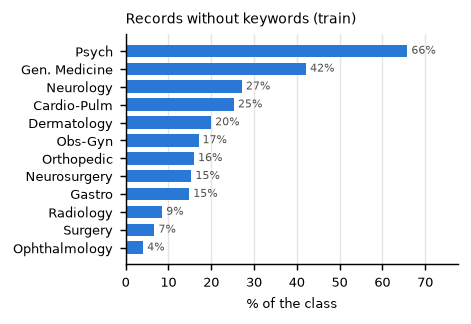

chi-square = 285, dof = 11, p = 1.5e-54


In [25]:
no_kw = train["keywords"] == ""
missing_kw = no_kw.groupby(train[TARGET]).mean().mul(100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(3.3, 2.3))
barh(ax, short(missing_kw.index), missing_kw.values, fmt="{:.0f}%",
     title="Records without keywords (train)", xlabel="% of the class")
save(fig, "keywords_missing_per_class")

# Lab 3: chi-square test of independence (H0: having keywords does not depend on the class)
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(train[TARGET], no_kw))
print(f"chi-square = {chi2:.0f}, dof = {dof}, p = {p:.1e}")

> **Observation 1: whether a record has keywords depends on its class.** 16.6% of train and 19.6% of test records have no keywords, from 66% of Psychiatry-Psychology and 42% of General Medicine down to 7% of Surgery and 4% of Ophthalmology (χ² test, p ≪ 0.05). An empty keyword field is itself informative, and a model that uses keywords must also work without them.

## 4. Distribution

### 4.1 Classes

,records,%
medical_specialty,,
Surgery,890,33.4
Cardiovascular-Pulmonary,308,11.6
Orthopedic,300,11.3
Radiology,222,8.3
General Medicine,211,7.9
Gastroenterology,195,7.3
Neurology,184,6.9
Obstetrics-Gynecology,135,5.1
Neurosurgery,78,2.9


imbalance ratio (largest / smallest class): 35.6 : 1
accuracy of always predicting 'Surgery': 33.4%
normalised entropy of the labels: 0.85


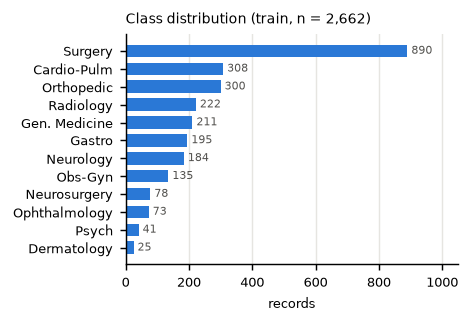

In [26]:
counts = train[TARGET].value_counts()
ORDER = counts.index.tolist()  # classes from largest to smallest, used in the rest of the notebook
display(pd.DataFrame({"records": counts, "%": counts.div(len(train)).mul(100).round(1)}))

print(f"imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1")
print(f"accuracy of always predicting '{ORDER[0]}': {counts.max() / len(train):.1%}")
# Lab 3: Shannon entropy, normalised so that 1 = perfectly balanced and 0 = a single class
print(f"normalised entropy of the labels: {stats.entropy(counts) / np.log(len(counts)):.2f}")

fig, ax = plt.subplots(figsize=(3.3, 2.3))
barh(ax, short(ORDER), counts.values, xlabel="records",
     title=f"Class distribution (train, n = {len(train):,})")
save(fig, "class_distribution")

### 4.2 Text length (words per field)

In [27]:
lengths = pd.DataFrame({col: train[col].str.split().str.len() for col in TEXT_COLS})
lengths.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T.round(1)

,count,mean,std,min,25%,50%,75%,90%,max
description,2662.0,18.9,12.2,0.0,9.0,16.0,26.0,36.0,76.0
sample_name,2662.0,3.8,1.4,1.0,3.0,4.0,5.0,6.0,8.0
transcription,2662.0,452.9,310.1,0.0,230.0,387.0,611.0,861.0,2454.0
keywords,2662.0,22.7,21.5,0.0,12.0,19.0,28.0,40.0,118.0


IQR outliers (> 1182 words): 71 transcriptions
longer than 512 words: 34% of the transcriptions
1 to 19 words (only a section header or one line): 31
median words per class: {'Radiology': 230, 'Dermatology': 254, 'Gastroenterology': 285, 'Ophthalmology': 323, 'Cardiovascular-Pulmonary': 358, 'Obstetrics-Gynecology': 387, 'Surgery': 405, 'Neurology': 419, 'General Medicine': 420, 'Orthopedic': 505, 'Neurosurgery': 538, 'Psychiatry-Psychology': 661}
Kruskal-Wallis H = 222, p = 1.9e-41


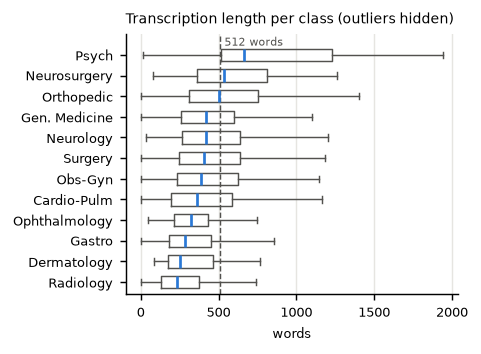

In [28]:
words = lengths["transcription"]
q1, q3 = words.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)

print(f"IQR outliers (> {upper:.0f} words): {(words > upper).sum()} transcriptions")
print(f"longer than 512 words: {(words > 512).mean():.0%} of the transcriptions")
print(f"1 to 19 words (only a section header or one line): {words.between(1, 19).sum()}")
print("median words per class:", words.groupby(train[TARGET]).median().sort_values().astype(int).to_dict())

# Lab 3: does the length depend on the class? (Kruskal-Wallis: no normality assumption)
H, p = stats.kruskal(*[words[train[TARGET] == label] for label in ORDER])
print(f"Kruskal-Wallis H = {H:.0f}, p = {p:.1e}")

order = words.groupby(train[TARGET]).median().sort_values().index
fig, ax = plt.subplots(figsize=(3.3, 2.6))
line = dict(color=INK, linewidth=0.8)
ax.boxplot([words[train[TARGET] == label] for label in order], orientation="horizontal",
           showfliers=False, widths=0.6, boxprops=line, whiskerprops=line, capprops=line,
           medianprops=dict(color=COLOR, linewidth=1.5))
ax.set_yticks(range(1, len(order) + 1), short(order))
ax.axvline(512, color=INK, linestyle="--", linewidth=0.8)
ax.set_ylim(0.4, len(order) + 1)
ax.text(512, len(order) + 0.6, " 512 words", color=INK, fontsize=6, va="center")
ax.grid(axis="y", visible=False)
ax.set(title="Transcription length per class (outliers hidden)", xlabel="words")
save(fig, "transcription_length_per_class")

In [29]:
train.loc[words.between(1, 19), [TARGET, "sample_name", "transcription"]].head(4)

,medical_specialty,sample_name,transcription
98,Cardiovascular-Pulmonary,Multilobar Pneumonia,"REASON FOR CONSULTATION: Loculated left effusion, multilobar pneumonia."
242,Cardiovascular-Pulmonary,Stress Test Thallium,"INDICATIONS:Chest pain.,STRESS TECHNIQUE:"
344,Gastroenterology,Laparoscopic Cholecystectomy - 6,PREOPERATIVE DIAGNOSIS: Cholelithiasis possible choledocholithiasis.
345,Gastroenterology,Flex Sig - 1,"INDICATION: Rectal bleeding.,PREMEDICATION: See procedure nurse NCS form.,PR..."


> **Observation 2: Surgery dominates and transcriptions are long.** Surgery has 890 records (33.4%) and Dermatology 25 (0.9%), a 35.6 : 1 ratio. Always predicting Surgery gives 33.4% accuracy but F1 = 0 for the other 11 classes, which fails the "every class F1 ≥ 25%" rule. The median transcription has 387 words, and 34% exceed 512 words, so also 512 sub-word tokens, the input limit of BERT-style models. Length depends on the class (Kruskal-Wallis, p ≪ 0.05): Radiology is the shortest (median 230 words), Psychiatry-Psychology the longest (661).

## 5. What does a label describe?

The 12 labels mix two taxonomies: **what kind of document** it is (operative note, consultation, imaging report) and **which organ system** it is about. `sample_name` is one level below the label (the procedure or visit).

### 5.1 Document type, from the section headers

Transcriptions are organised in upper-case headers (`PREOPERATIVE DIAGNOSIS:`, `IMPRESSION:`, ...). This is a fixed surface pattern, so a regular expression is the right tool here.

In [30]:
HEADER = re.compile(r"(?:^|(?<=[.,:]))\s*([A-Z][A-Z /&()\-]{2,40}?)\s*:")
headers = train["transcription"].map(lambda t: {h.strip() for h in HEADER.findall(t)})

pd.Series(Counter(h for hs in headers for h in hs)).nlargest(15).rename("documents")

ANESTHESIA                    839
PROCEDURE                     776
PREOPERATIVE DIAGNOSIS        766
POSTOPERATIVE DIAGNOSIS       699
COMPLICATIONS                 522
IMPRESSION                    438
FINDINGS                      431
ESTIMATED BLOOD LOSS          420
PROCEDURE PERFORMED           415
POSTOPERATIVE DIAGNOSES       340
HISTORY OF PRESENT ILLNESS    298
PREOPERATIVE DIAGNOSES        298
DESCRIPTION OF PROCEDURE      276
EXAM                          266
INDICATIONS                   263
Name: documents, dtype: int64

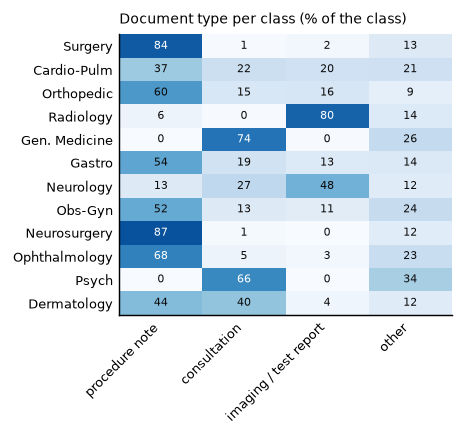

In [31]:
NOTE_TYPES = {  # first match wins
    "procedure note": {"PREOPERATIVE DIAGNOSIS", "PREOPERATIVE DIAGNOSES",
                       "POSTOPERATIVE DIAGNOSIS", "POSTOPERATIVE DIAGNOSES",
                       "ANESTHESIA", "ESTIMATED BLOOD LOSS", "PROCEDURE PERFORMED",
                       "PROCEDURE IN DETAIL", "DESCRIPTION OF PROCEDURE",
                       "DESCRIPTION OF OPERATION", "OPERATIVE PROCEDURE", "NAME OF PROCEDURE"},
    "consultation": {"CHIEF COMPLAINT", "HISTORY OF PRESENT ILLNESS", "REVIEW OF SYSTEMS",
                     "SUBJECTIVE", "REASON FOR CONSULTATION", "REASON FOR VISIT", "HPI", "CC"},
    "imaging / test report": {"EXAM", "IMPRESSION", "FINDINGS", "TECHNIQUE",
                              "CONCLUSION", "INTERPRETATION"},
}

def note_type(hs):
    return next((name for name, markers in NOTE_TYPES.items() if hs & markers), "other")

doc_type = headers.map(note_type)
by_class = pd.crosstab(train[TARGET], doc_type, normalize="index").mul(100)
by_class = by_class.loc[ORDER, [*NOTE_TYPES, "other"]]
by_class.index = short(by_class.index)

fig, ax = plt.subplots(figsize=(3.3, 2.8))
heatmap(ax, by_class, vmax=100, title="Document type per class (% of the class)")
save(fig, "document_type_per_class")

### 5.2 `sample_name`, one level below the label

In [32]:
name = train["sample_name"].str.replace(r"\s*-\s*\d+$", "", regex=True)  # "Colonoscopy - 3" -> "Colonoscopy"
classes_per_name = train.groupby(name)[TARGET].nunique()
majority = train.groupby(name)[TARGET].agg(lambda s: s.value_counts().iloc[0]).sum()

print(f"distinct sample names: {train['sample_name'].nunique():,} "
      f"-> {name.nunique():,} without the ' - N' suffix")
print(f"names used by more than one class: {(classes_per_name > 1).sum()} "
      f"({(classes_per_name > 1).mean():.0%})")
print(f"accuracy of 'majority class of the sample name' on train: {majority / len(train):.1%}")

for example in ["Anterior Cervical Discectomy & Fusion", "Colonoscopy", "Gen Med Consult"]:
    print(f"  {example!r}: {train.loc[name == example, TARGET].value_counts().to_dict()}")

distinct sample names: 1,852 -> 1,333 without the ' - N' suffix
names used by more than one class: 538 (40%)
accuracy of 'majority class of the sample name' on train: 68.5%
  'Anterior Cervical Discectomy & Fusion': {'Orthopedic': 9, 'Neurosurgery': 8, 'Surgery': 8}
  'Colonoscopy': {'Gastroenterology': 20, 'Surgery': 17}
  'Gen Med Consult': {'General Medicine': 43}


> **Observation 3: three labels name a type of document, the other nine an organ system.** By section headers, 84% of Surgery and 87% of Neurosurgery records are procedure notes, 80% of Radiology are imaging/test reports, and 74% of General Medicine and 66% of Psychiatry-Psychology are consultations. Organ-system classes are also largely procedure notes (Orthopedic 60%, Ophthalmology 68%). So a knee operation is legitimately both *Surgery* and *Orthopedic*: the same procedure name appears under several classes (*Anterior Cervical Discectomy & Fusion*: 9 Orthopedic, 8 Neurosurgery, 8 Surgery).

## 6. Sparsity and correlation

### 6.1 Sparsity of the word space

In [33]:
TOKEN = re.compile(r"[a-z][a-z'\-]+")
docs = [TOKEN.findall(t.lower()) for t in train["transcription"]]
term_freq = Counter(w for d in docs for w in d)
nonzero = sum(len(set(d)) for d in docs)

print(f"tokens: {sum(term_freq.values()):,} | vocabulary: {len(term_freq):,} words")
print(f"document-term matrix {len(docs):,} x {len(term_freq):,}: "
      f"{nonzero / (len(docs) * len(term_freq)):.2%} of the cells are non-zero")
print(f"distinct words per document (mean): {nonzero / len(docs):.0f}")
print("most frequent:", ", ".join(w for w, _ in term_freq.most_common(10)))

tokens: 1,171,206 | vocabulary: 20,170 words
document-term matrix 2,662 x 20,170: 0.99% of the cells are non-zero
distinct words per document (mean): 199
most frequent: the, was, and, of, to, with, in, patient, is, were


### 6.2 Between records: the same report under several labels

In [34]:
has_text = train[train["transcription"] != ""]
groups = has_text.groupby("transcription")[TARGET].agg(list)
shared = groups[groups.map(len) > 1]
in_shared = has_text["transcription"].isin(shared.index)

print(f"{in_shared.sum():,} of {len(train):,} records ({in_shared.sum() / len(train):.0%}) "
      f"share their transcription with another record")
print(f"{len(shared)} groups of identical transcriptions, "
      f"{sum(len(set(g)) > 1 for g in shared)} of them with different labels")
print(f"distinct transcriptions: {has_text['transcription'].nunique():,} "
      f"for {len(has_text):,} records with a transcription")
print(f"groups that involve Surgery: {np.mean(['Surgery' in g for g in shared]):.0%}")

# Upper bound for a model that only reads the transcription:
# in a group of identical texts, at most the most frequent label can be right.
best = has_text.groupby("transcription")[TARGET].agg(lambda s: s.value_counts().iloc[0]).sum()
print(f"best possible train accuracy from the transcription alone: "
      f"{(best + (train['transcription'] == '').sum()) / len(train):.0%}")

1,535 of 2,662 records (58%) share their transcription with another record
733 groups of identical transcriptions, 732 of them with different labels
distinct transcriptions: 1,836 for 2,638 records with a transcription
groups that involve Surgery: 73%
best possible train accuracy from the transcription alone: 70%


One example: the copies differ **only** in the label and the first keyword.

In [35]:
copies = has_text[in_shared].assign(
    other_keywords=lambda d: d["keywords"].str.split(",", n=1).str[1].fillna(""))
identical = copies.groupby("transcription")[["description", "sample_name", "other_keywords"]].nunique().eq(1)
print("groups where the field is identical across copies:", identical.sum().to_dict(), "of", len(identical))

example = shared[shared.map(len) == 3].index[0]
(has_text.loc[has_text["transcription"] == example, [TARGET, "sample_name", "keywords"]]
 .assign(keywords=lambda d: d["keywords"].str[:50] + "..."))

groups where the field is identical across copies: {'description': 732, 'sample_name': 732, 'other_keywords': 725} of 733


,medical_specialty,sample_name,keywords
982,Neurosurgery,Anterior Cervical Discectomy - 2,"neurosurgery, herniated nucleus pulposus, anterior..."
1301,Orthopedic,Anterior Cervical Discectomy - 2,"orthopedic, herniated nucleus pulposus, anterior c..."
2294,Surgery,Anterior Cervical Discectomy - 2,"surgery, herniated nucleus pulposus, anterior cerv..."


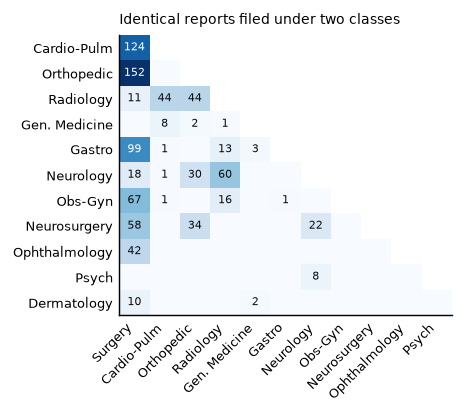

% of each class whose transcription also appears under another class:
{'Surgery': 61, 'Cardiovascular-Pulmonary': 58, 'Orthopedic': 71, 'Radiology': 73, 'General Medicine': 8, 'Gastroenterology': 60, 'Neurology': 55, 'Obstetrics-Gynecology': 65, 'Neurosurgery': 92, 'Ophthalmology': 58, 'Psychiatry-Psychology': 20, 'Dermatology': 48}


In [36]:
pairs = pd.DataFrame(0, index=ORDER, columns=ORDER)
for labels in shared:
    for a, b in combinations(sorted(set(labels)), 2):
        pairs.loc[a, b] += 1
        pairs.loc[b, a] += 1

lower = pairs.where(np.tril(np.ones(pairs.shape, dtype=bool), k=-1))  # symmetric: keep one half
lower = lower.iloc[1:, :-1]
lower.index, lower.columns = short(lower.index), short(lower.columns)

fig, ax = plt.subplots(figsize=(3.3, 2.8))
heatmap(ax, lower, hide=0, title="Identical reports filed under two classes")
save(fig, "shared_reports_between_classes")

print("% of each class whose transcription also appears under another class:")
print(in_shared.groupby(has_text[TARGET]).mean().mul(100).round(0).loc[ORDER].astype(int).to_dict())

### 6.3 Between fields: keywords ↔ label

In [37]:
KEYWORD_TO_LABEL = {label.lower().replace("-", " / "): label for label in LABELS}  # "obstetrics / gynecology"

def keyword_label(keywords):
    """Label written as the first keyword, or None if the first keyword is not a label."""
    return KEYWORD_TO_LABEL.get(keywords.split(",", 1)[0].strip().lower())

has_kw = train["keywords"] != ""
kw_label = train.loc[has_kw, "keywords"].map(keyword_label)
test_kw_label = test["keywords"].map(keyword_label)

print(f"train records with keywords: {has_kw.sum():,}; "
      f"first keyword == label in {(kw_label == train.loc[has_kw, TARGET]).mean():.1%} of them")
print(f"test records whose first keyword is a label: {test_kw_label.notna().sum()} "
      f"of {len(test)} ({test_kw_label.notna().mean():.0%})")

(pd.DataFrame({"train %": train[TARGET].value_counts(normalize=True),
               f"test % (first keyword, n = {test_kw_label.notna().sum()})":
                   test_kw_label.value_counts(normalize=True)})
 .mul(100).round(1).loc[ORDER])

train records with keywords: 2,219; first keyword == label in 100.0% of them
test records whose first keyword is a label: 320 of 398 (80%)


,train %,"test % (first keyword, n = 320)"
Surgery,33.4,42.2
Cardiovascular-Pulmonary,11.6,10.0
Orthopedic,11.3,7.8
Radiology,8.3,10.0
General Medicine,7.9,3.8
Gastroenterology,7.3,7.5
Neurology,6.9,5.3
Obstetrics-Gynecology,5.1,4.7
Neurosurgery,2.9,3.4
Ophthalmology,2.7,2.5


### 6.4 Between train and test

In [38]:
train_labels = has_text.groupby("transcription")[TARGET].agg(set)
in_train = test["transcription"].isin(train_labels.index)
check = test[in_train & test_kw_label.notna()]
same = [test_kw_label[i] in train_labels[t] for i, t in check["transcription"].items()]

print(f"test transcriptions that also occur in train: {in_train.sum()} of {len(test)} "
      f"({in_train.mean():.0%})")
print(f"of these, with a keyword label: {len(check)}; "
      f"test label equal to a train label of the same text: {sum(same)}")

pd.DataFrame({"test label (keyword)": test_kw_label[check.index],
              "train label(s) of the same text": check["transcription"].map(
                  lambda t: " + ".join(sorted(train_labels[t])))}).value_counts().head(6)

test transcriptions that also occur in train: 240 of 398 (60%)
of these, with a keyword label: 210; test label equal to a train label of the same text: 0


test label (keyword)      train label(s) of the same text
Surgery                   Orthopedic                         22
                          Gastroenterology                   18
Cardiovascular-Pulmonary  Surgery                            17
Orthopedic                Surgery                            15
Gastroenterology          Surgery                            15
Surgery                   Cardiovascular-Pulmonary           12
Name: count, dtype: int64

In [39]:
# Does a random split of train reproduce this overlap?
rng = np.random.default_rng(0)
overlap = []
for _ in range(20):
    idx = rng.permutation(len(train))
    val, rest = train.iloc[idx[:len(test)]], train.iloc[idx[len(test):]]
    seen = set(rest["transcription"]) - {""}
    overlap.append(val["transcription"].isin(seen).mean())
print(f"random split (validation = {len(test)} records): "
      f"{np.mean(overlap):.0%} ± {np.std(overlap):.0%} of validation texts also in the training part")

random split (validation = 398 records): 50% ± 2% of validation texts also in the training part


> **Observation 4: the dataset is multi-label in disguise.** 58% of the training records (1,535) share their transcription with another record, and in 732 of the 733 groups of identical texts the labels differ. The copies differ only in the label and the first keyword (description and sample name are identical in 732 of 733 groups). Surgery is in 73% of these groups (mostly with Orthopedic, Cardiovascular-Pulmonary and Gastroenterology). So no model that reads only the transcription can exceed **≈70% accuracy** on train.
>
> **Observation 5: the first keyword *is* the label.** True for 100% of the 2,219 training records with keywords; 80% of the test records (320/398) have such a keyword. It is also the only field that tells the copies of Obs. 4 apart.
>
> **Observation 6: train and test share texts, never labels.** 60% of the test transcriptions (240) also occur in train, and for all 210 of them with a keyword the test label differs from the train label of the same text (e.g. Orthopedic in train → Surgery in test). A model that memorises training texts is wrong on these by construction. A random split of train reproduces this (≈50% overlap), so it mirrors the official test set.

## 7. Looking at the text

### 7.1 Which words characterise each class?

Log-odds ratio with an informative Dirichlet prior (Monroe et al., 2008): a z-score of how much more a class uses a word than all other classes. **Stop words are kept on purpose** (Lab 4 removes them before counting; the project statement warns against doing it blindly).

In [40]:
def characteristic_words(texts, labels, top=8, min_count=10, prior=1000.0):
    counts = {label: Counter() for label in ORDER}
    for label, text in zip(labels, texts):
        counts[label].update(TOKEN.findall(text.lower()))
    total = sum(counts.values(), Counter())
    vocab = [w for w, c in total.items() if c >= min_count]
    y_all = np.array([total[w] for w in vocab], float)
    alpha = y_all / y_all.sum() * prior
    table = {}
    for label in ORDER:
        y_in = np.array([counts[label][w] for w in vocab], float)
        y_out = y_all - y_in
        n_in, n_out = y_in.sum(), y_out.sum()
        delta = (np.log((y_in + alpha) / (n_in + prior - y_in - alpha))
                 - np.log((y_out + alpha) / (n_out + prior - y_out - alpha)))
        z = delta / np.sqrt(1 / (y_in + alpha) + 1 / (y_out + alpha))
        table[label] = ", ".join(vocab[i] for i in np.argsort(-z)[:top])
    return pd.Series(table, name="most characteristic words (transcription)").to_frame()

characteristic_words(train["transcription"], train[TARGET])

,most characteristic words (transcription)
Surgery,"the, was, then, procedure, placed, were, incision, anesthesia"
Cardiovascular-Pulmonary,"artery, coronary, pulmonary, chest, ventricular, heart, atrial, catheter"
Orthopedic,"knee, joint, fracture, tendon, medial, tourniquet, pain, foot"
Radiology,"there, normal, exam, is, unremarkable, images, are, impression"
General Medicine,"no, or, is, has, history, negative, he, she"
Gastroenterology,"colon, stomach, gallbladder, esophagus, scope, colonoscopy, duct, abdominal"
Neurology,"he, she, her, unremarkable, mri, his, brain, gait"
Obstetrics-Gynecology,"uterus, uterine, cervix, vaginal, pelvic, fetal, delivery, pregnancy"
Neurosurgery,"bone, dura, tumor, cervical, decompression, screws, disk, discectomy"
Ophthalmology,"eye, chamber, lens, lid, cataract, intraocular, corneal, speculum"


> **Observation 7: the document-type classes are recognised by style, not topic.** Surgery's most characteristic words are *the, was, then, procedure, placed, incision* (the past-tense story of an operation); Radiology gets *there, normal, exam, is, unremarkable, impression*; General Medicine gets *no, or, is, has, history, negative* (negated findings). Organ-system classes get anatomy (*knee, fracture, tendon*; *colon, stomach*; *eye, lens, cataract*). Removing stop words would delete the main signal of the largest classes.

### 7.2 Artefacts to clean (same treatment for train and test)

In [41]:
ARTEFACTS = [  # (what, field, regex)
    ("website disclaimer glued to the keywords", "keywords", r"NOTE\s*,?\s*:\s*These\s*transcribed"),
    ("line breaks flattened into '.,'", "transcription", r"\.,\S"),
    ("anonymisation placeholders (Dr. X, XYZ, ABC)", "transcription", r"\bDr\. [A-Z]\b|\bXYZ\b|\bABC\b"),
    ("numbered sample name ('Colonoscopy - 3')", "sample_name", r"-\s*\d+$"),
    ("non-ASCII characters", "transcription", r"[^\x00-\x7f]"),
]
rows = []
for what, field, pattern in ARTEFACTS:
    hits = train[field].str.contains(pattern, regex=True)
    match = re.search(pattern, train.loc[hits, field].iloc[0]).group()
    rows.append((what, field, match, hits.sum(), test[field].str.contains(pattern, regex=True).sum()))
pd.DataFrame(rows, columns=["artefact", "field", "example", "train records", "test records"])

,artefact,field,example,train records,test records
0,website disclaimer glued to the keywords,keywords,"NOTE,: Thesetranscribed",150,10
1,"line breaks flattened into '.,'",transcription,".,S",2569,388
2,"anonymisation placeholders (Dr. X, XYZ, ABC)",transcription,Dr. X,524,74
3,numbered sample name ('Colonoscopy - 3'),sample_name,- 1,864,130
4,non-ASCII characters,transcription,’,55,7


These are left for the preprocessing of the models (the disclaimer is pure noise; `.,` should become a line break).

## 8. Summary for the paper

**Dataset.** 2,662 training records (after the repair) and 398 test records; 4 free-text inputs (`description`, `sample_name`, `transcription`, `keywords`) and 12 labels. Imbalanced: Surgery 33.4% vs. Dermatology 0.9% (35.6 : 1). Median transcription 387 words, 34% above 512. Vocabulary 20.2k words, document-term matrix 99% empty. Figures: `class_distribution.pdf`, `transcription_length_per_class.pdf`.

**Observations** (the template asks for ≥ 2; the strongest in the paper, the rest in the appendix):

| # | observation | key numbers | figure |
|---|---|---|---|
| 0 | corrupted CSV, naive parsing merges records | 15 labels, 32,759-char fields, 7 records lost | — |
| 1 | missing keywords depend on the class | Psych 66% vs. Ophthalmology 4% | `keywords_missing_per_class.pdf` |
| 2 | imbalance and long texts | 35.6 : 1; 34% > 512 words | `class_distribution.pdf` |
| 3 | 3 labels = document type, 9 = organ system | 84% of Surgery are procedure notes | `document_type_per_class.pdf` |
| 4 | same report under several labels | 58% of records; text-only ceiling ≈ 70% | `shared_reports_between_classes.pdf` |
| 5 | first keyword = label | 100% of train; 80% of test | — |
| 6 | train and test share texts, never labels | 60% of test texts in train; 210/210 differ | — |
| 7 | "style" classes defined by function words | Surgery: *the, was, then, placed* | table in §7.1 |

**What this means for the next sections**

* *Experimental setup*: use `data/clean_train.csv`, not `pd.read_csv("train.csv")`. A random stratified split of train behaves like the official test (Obs. 6). `results.txt` must have 398 lines.
* *Research question*: how much comes from the keyword shortcut (Obs. 5) vs. the clinical text? Compare models with and without `keywords`; 20% of the test set has none anyway (Obs. 1).
* *Models*: do not remove stop words blindly (Obs. 7); decide how to handle texts longer than 512 tokens (Obs. 2); report macro-F1 and per-class F1, not only accuracy.
* *Discussion*: expect Surgery ↔ organ-specialty and Radiology ↔ Neurology/Cardio confusions (Obs. 3–4). Many such "errors" are labels we could argue with, which the project statement asks us to discuss.